# Residual Analysis: Multiple Energy Bins

This notebook demonstrates the two ways to use `ResidualAnalysis` when the observed and expected histograms contain multiple measured-energy (`Em`) bins:

1. Preserve every original `Em` bin to study energy-resolved CDS residuals.
2. Select an interval with `select_energy_range(energy_min, energy_max)` and aggregate its bins before calculating standard CDS residuals.

Both workflows start from the same analysis object and use the same masked observed and expected counts. Selecting an interval returns a new object and does not modify the original multi-energy analysis.

> **Important data-provenance note:** This notebook uses an artificial multi-energy demonstration product derived from the stored DC4 511 keV residual product. Its embedded metadata records `product_type=artificial_multienergy_test`, the DC4 source file, a random seed, energy edges, and scale-factor arrays. The repository does not provide an independent fitted multi-energy residual product for this tutorial.
>
> The fixture is used because its explicit `Em` dimension can demonstrate energy-resolved projections, `energy_bin_index` map selection, and multi-bin aggregation with `select_energy_range()`. These residuals test and illustrate the class interface; they must not be interpreted as scientific evidence for the quality of an independent multi-energy fit.

## Setup

The following cells locate the `workflow` directory and import the histogram, residual-analysis, plotting, and display tools used in this notebook.

In [20]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)

# Make the local workflow modules importable.
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
from IPython.display import display
import h5py
import numpy as np

## Load the residual products

`ResidualAnalysis` requires an observed-count histogram and the corresponding fitted expected-count histogram. The two histograms must have identical axes and shapes, and their counts must be finite and non-negative.

This notebook uses `workflow/data/residual/test_multienergy_residual_products.hdf5`. Embedded metadata identifies it as an `artificial_multienergy_test` derived from `03_511_imaging_residual_products.hdf5`, with a recorded random seed and energy-dependent scale factors. The repository does not contain a separate multi-energy fit that produced this file, so it must be treated as a demonstration/simulation fixture rather than a genuine fitted multi-energy DC4 result.

To analyze another product, change `residual_file` and, if necessary, the `name` values used to load `observed` and `expected`. HDF5 object names can differ, so inspect them before calling `Histogram.open()`.

In [22]:
# Locate the multi-energy residual product.
residual_dir = repo_root / "data" / "residual"
residual_file = residual_dir / "test_multienergy_residual_products.hdf5"

print("Input file:", residual_file)
print("File exists:", residual_file.exists())

Input file: /Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/test_multienergy_residual_products.hdf5
File exists: True


In [23]:
# Inspect the available objects before choosing histogram names.
with h5py.File(residual_file, "r") as residual_data:
    available_objects = list(residual_data.keys())

print("Available objects:", available_objects)

Available objects: ['background_expectation', 'observed', 'simulation_metadata', 'source_expectation', 'total_expectation']


### Confirm the product provenance

Always inspect provenance before interpreting residuals. This tutorial file is deliberately marked as an artificial multi-energy test product. The following cell reads both its attributes and stored metadata arrays; these describe the fixture and are not a fitted multi-energy result.

In [24]:
# Read all provenance recorded with the existing tutorial fixture.
with h5py.File(residual_file, "r") as residual_data:
    metadata_group = residual_data["simulation_metadata"]
    simulation_metadata = dict(metadata_group.attrs)
    simulation_metadata_arrays = {
        name: metadata_group[name][()]
        for name in metadata_group.keys()
    }

display(simulation_metadata)
display(simulation_metadata_arrays)

{'product_type': 'artificial_multienergy_test',
 'random_seed': np.int64(20261014),
 'source_energy_bin_keV': array([509., 513.]),
 'source_file': '/Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/03_511_imaging_residual_products.hdf5'}

{'background_scale_factors': array([0.8, 1.2, 0.9]),
 'energy_bin_edges_keV': array([300., 400., 600., 800.]),
 'source_scale_factors': array([0.6 , 1.  , 0.45])}

In [25]:
# Load the observed counts and total fitted expectation.
# Replace these names if the previous cell reports different objects.
observed = Histogram.open(
    residual_file,
    name="observed",
)

expected = Histogram.open(
    residual_file,
    name="total_expectation",
)

## Verify the input structure

Inspect both histograms before initializing the analysis. This example must report more than one `Em` bin. If a file reports one bin, no energy selection is required; use the single-bin tutorial instead.

The printed `Em` edges are also the only valid limits for `select_energy_range()`.

In [26]:
# Confirm that both histograms have matching dimensions.
energy_bin_count = observed.axes["Em"].nbins
energy_edges = observed.axes["Em"].edges
energy_edges_keV = energy_edges.to_value("keV")

print("Observed axes:", observed.axes.labels)
print("Expected axes:", expected.axes.labels)
print("Observed shape:", observed.shape)
print("Expected shape:", expected.shape)
print("Number of Em bins:", energy_bin_count)
print("Available Em edges:", energy_edges)
print("Indexed Em edges:")
for edge_index, edge_keV in enumerate(energy_edges_keV):
    print(f"  edge {edge_index}: {edge_keV:g} keV")

if energy_bin_count <= 1:
    raise ValueError(
        "This tutorial requires an input containing multiple Em bins."
    )

Observed axes: ['Em' 'Phi' 'PsiChi']
Expected axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (3, 60, 3072)
Expected shape: (3, 60, 3072)
Number of Em bins: 3
Available Em edges: [300. 400. 600. 800.] keV
Indexed Em edges:
  edge 0: 300 keV
  edge 1: 400 keV
  edge 2: 600 keV
  edge 3: 800 keV


## Initialize the full multi-energy analysis

Initialize one `ResidualAnalysis` object from the complete matching histograms. No energy bins are selected or combined at this stage, so `full_analysis` preserves the original `Em` axis.

In [27]:
# Preserve every original Em bin during initialization.
# Add expected_floor=<known value> only when the model uses such a floor.
full_analysis = ResidualAnalysis(
    observed,
    expected,
)

## Workflow A: Preserve the original energy bins

The loaded file contains multiple `Em` bins, so the first workflow preserves energy. It shows the energy spectrum, an energy-versus-`Phi` residual map, and one energy slice of the `PsiChi` HEALPix residual cube:

1. Calculate an energy-resolved residual histogram.
2. Initialize `PlottingResiduals` with the full analysis.
3. Plot representative energy-resolved projections.

The example uses raw residuals and therefore requires no Poisson simulations. The direct `Em-Phi` residual variable is available for numerical work; `plot()` obtains its own projected residuals from `full_analysis`. `energy_bin_index` selects only the displayed HEALPix slice and does not remove or aggregate any bin.

In [28]:
# Calculate one energy-resolved residual histogram.
standard_em_phi_residual = full_analysis.residual_function(
    "Em_Phi_projection",
    residual_type="raw",
)


In [29]:

# Initialize the plotting interface from the same analysis object.
standard_energy_plotter = PlottingResiduals(full_analysis)

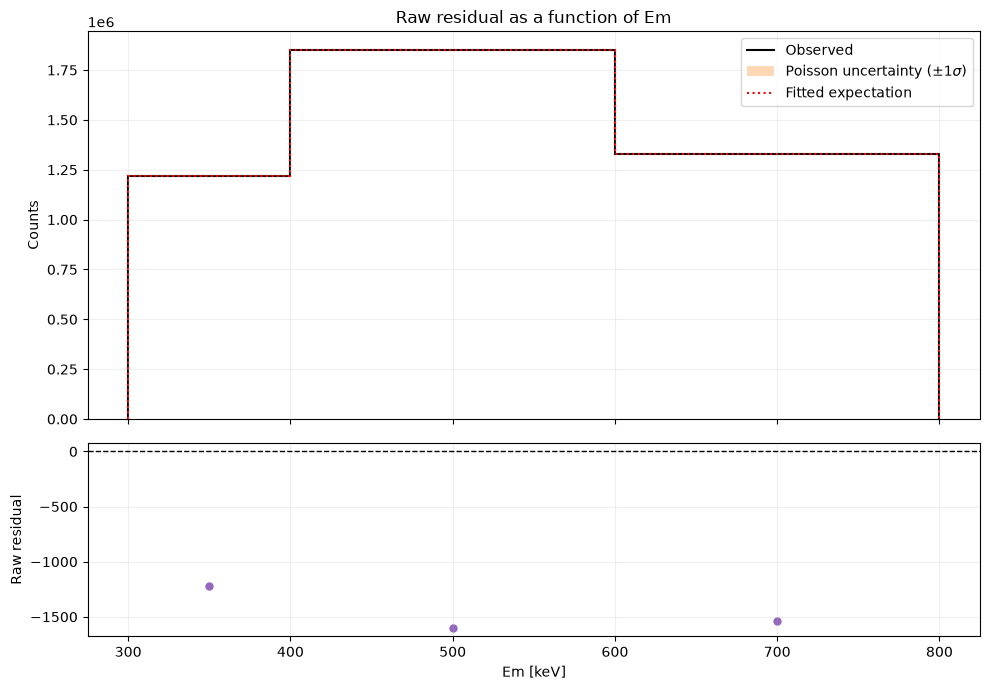

In [30]:
# Show total observed and expected counts versus measured energy.
standard_em_figure = standard_energy_plotter.plot(
    "Em_projection",
    residual_type="raw",
)


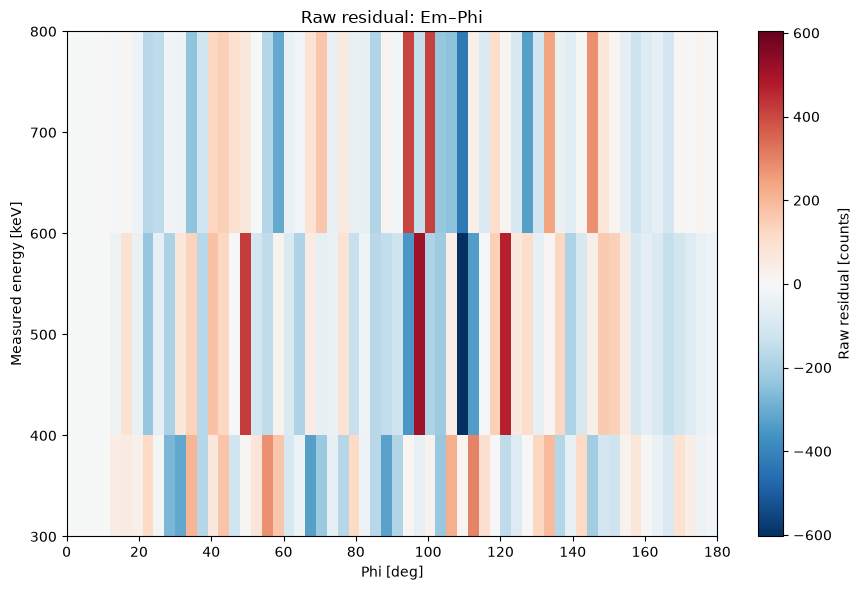

In [31]:
# Show residuals versus energy and Phi while preserving every Em bin.
standard_em_phi_figure = standard_energy_plotter.plot(
    "Em_Phi_projection",
    residual_type="raw",
)

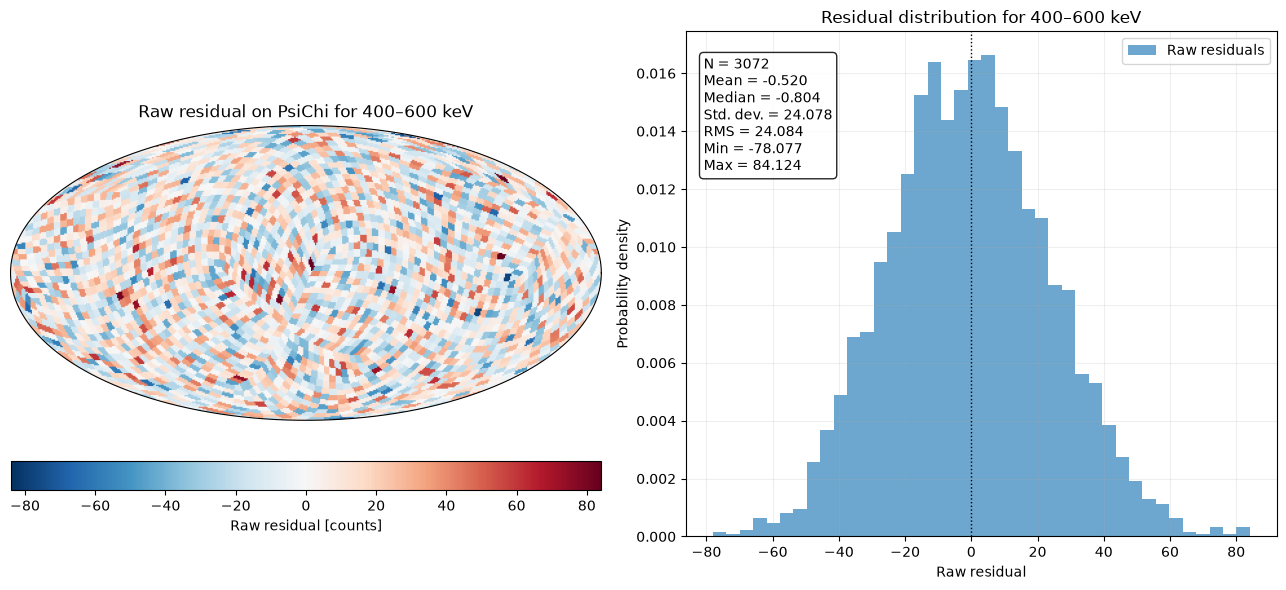

Residual axes: ['Em' 'Phi']
Residual shape: (3, 60)


In [32]:
# Modify this zero-based variable to display another original energy bin.
energy_bin_index = 1
standard_em_psichi_figure = standard_energy_plotter.plot(
    "Em_PsiChi_projection",
    residual_type="raw",
    energy_bin_index=energy_bin_index,
)

print("Residual axes:", standard_em_phi_residual.axes.labels)
print("Residual shape:", standard_em_phi_residual.shape)

<a id="energy-range-selection"></a>

## Workflow B: Select and aggregate an energy interval

When the goal is one combined energy band, `select_energy_range()` requires physical energy limits that coincide with existing `Em` edges. Every original bin between `energy_min` and `energy_max` is aggregated into one.

In the next cell, **`energy_min` and `energy_max` are the only variables users need to modify**. The current values select 300 to 600 keV, which combines the first two original energy bins. The returned one-bin analysis supports the standard CDS residual projections.

In [33]:
# Case 1: Aggregate multiple energy bins: 300–400 and 400–600 keV.
range_analysis = full_analysis.select_energy_range(
    300.0,
    600.0,
)


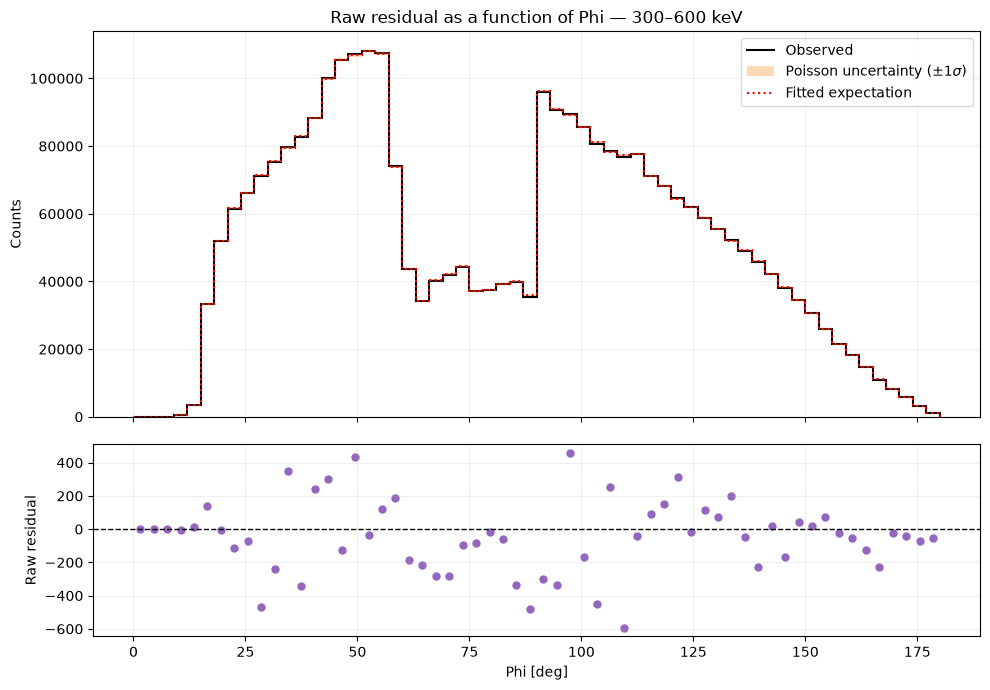

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


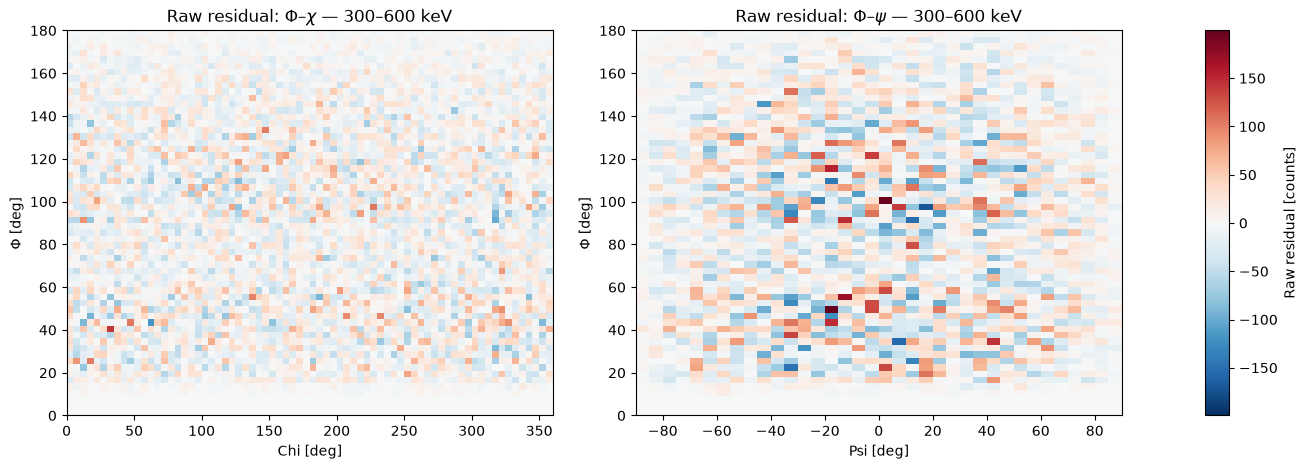

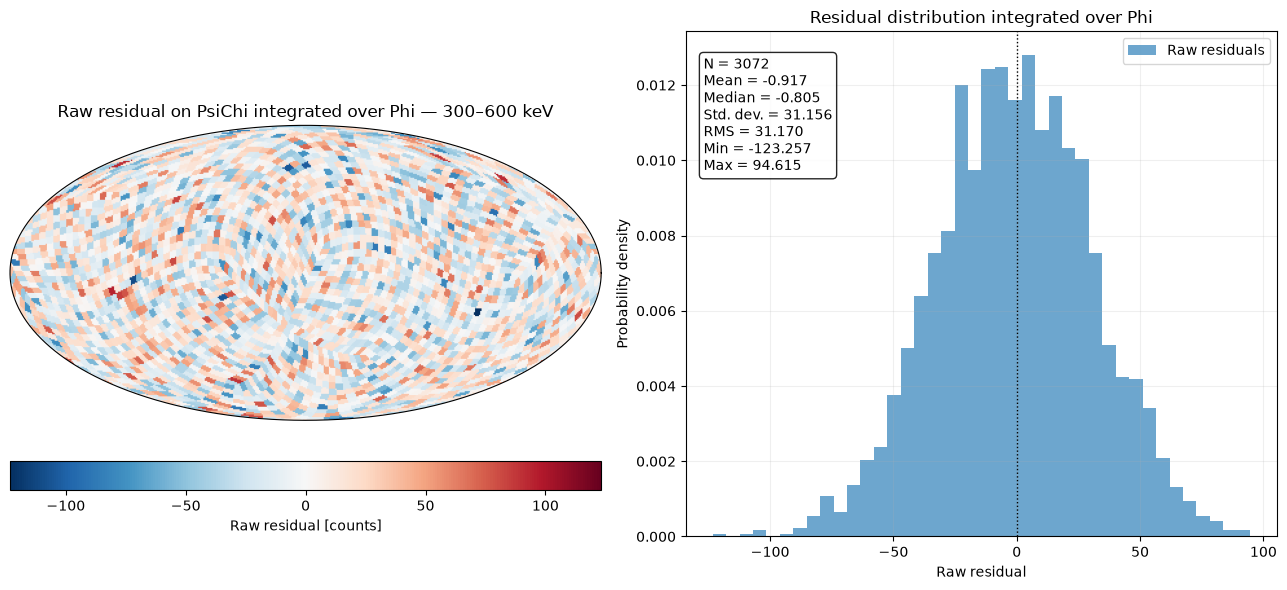

In [34]:
# Plot the selected single energy bin.
range_plotter = PlottingResiduals(range_analysis)

range_phi_figure = range_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

range_angular_figure = range_plotter.plot(
    "Phi_Chi_projection",
    residual_type="raw",
)

range_psichi_figure = range_plotter.plot(
    "PsiChi_projection",
    residual_type="raw",
)

### Plot energy-resolved residuals

`n_simulations` enables fixed-fit Poisson reference distributions for Pearson residuals, and `random_seed` makes those simulations reproducible. Increase `n_simulations` for a smoother final reference.

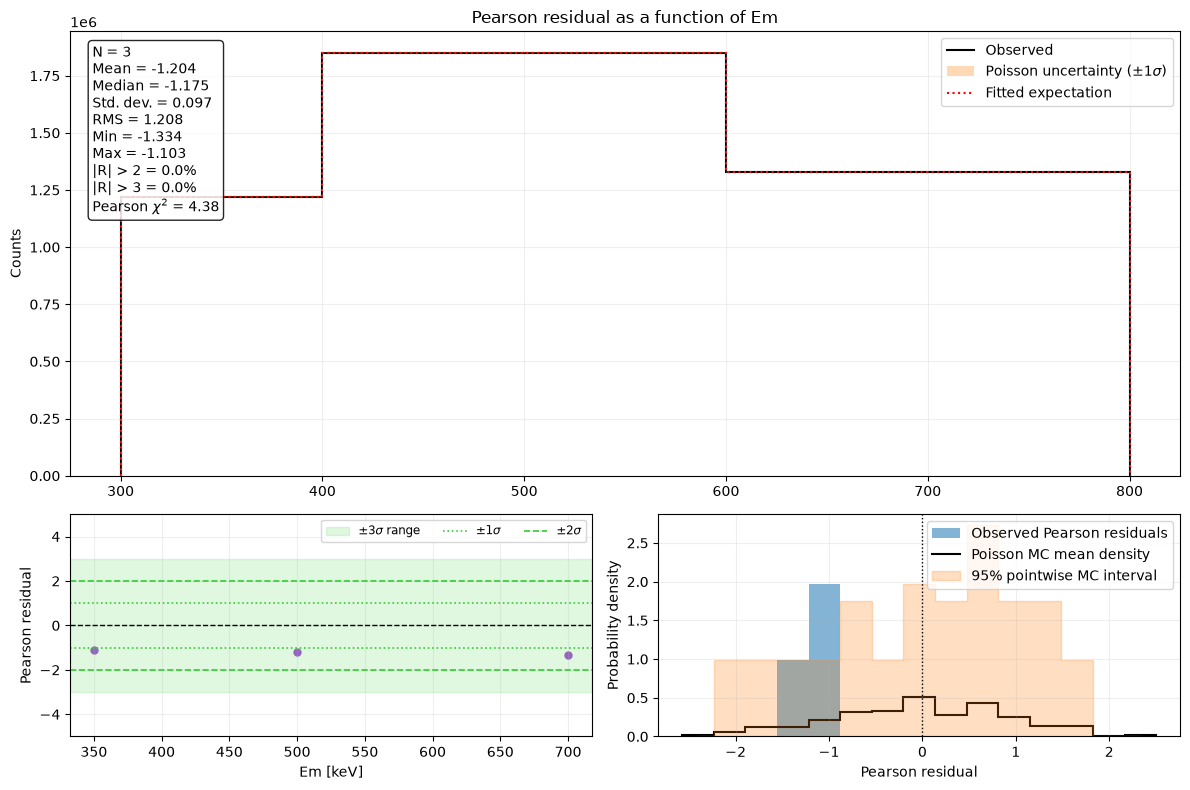

In [35]:
# Modify these values to control Monte Carlo cost and reproducibility.
n_simulations = 50
random_seed = 42

# Configure the plotter once and reuse it for this analysis object.
energy_resolved_plotter = PlottingResiduals(
    full_analysis,
    n_simulations=n_simulations,
    random_seed=random_seed,
)

# Em_projection integrates CDS coordinates but preserves every Em bin.
em_figure = energy_resolved_plotter.plot(
    "Em_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

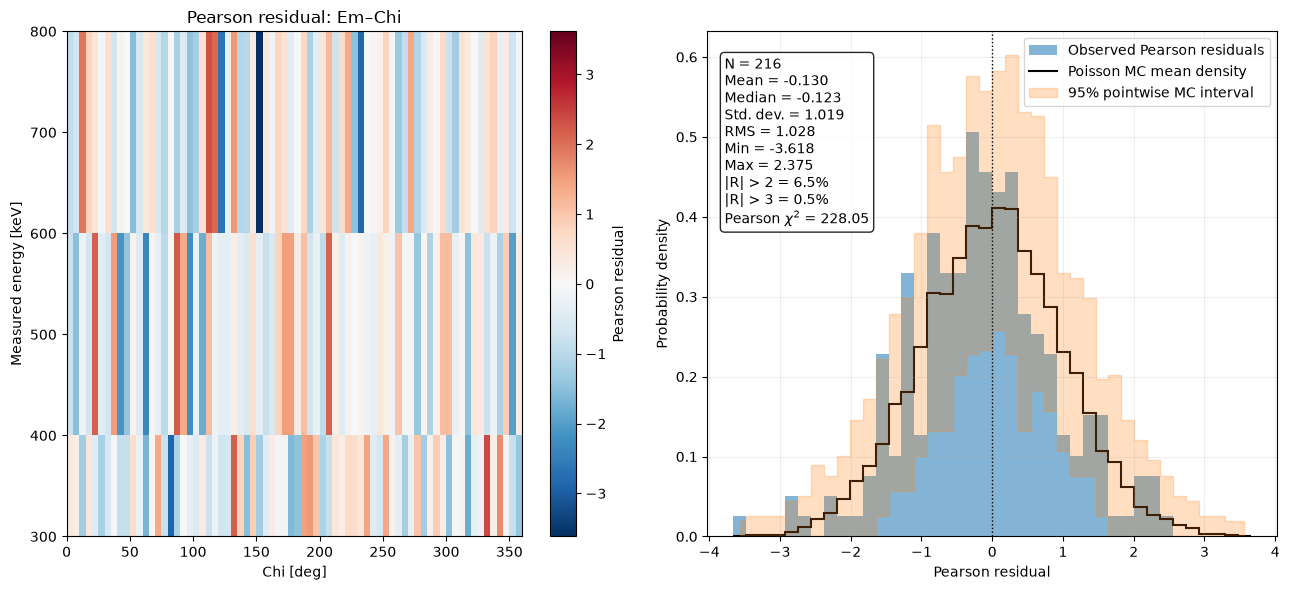

In [36]:
# Em_Chi_projection displays residuals versus energy and Chi.
# Replace it with Em_Phi_projection or Em_Psi_projection for those views.
em_chi_figure = energy_resolved_plotter.plot(
    "Em_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

### Display the statistics table

- **Notes:** It is intentionally unavailable on `full_analysis` while multiple `Em` bins remain. The table is descriptive and does not include fitted degrees of freedom or a goodness-of-fit probability.

In [37]:
# Use "raw" or "fractional" for the other residual definitions.
display(range_analysis.statistics_table("pearson"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,-0.004631,-0.066489,0.975073,0.975084,-3.641611,11.526978,4.166667,0.520291,175249.352805,171014.691196


In [38]:
# Summarize the observed data and expected model across all energy bins.
display(full_analysis.data_summary_table())

,Statistic,Value
0,Em bins,3
1,Em edges [keV],"(300.0, 400.0, 600.0, 800.0)"
2,Phi bins,60
3,Phi range [deg],"(0.0, 180.0)"
4,PsiChi bins,3072
5,PsiChi HEALPix nside,16
6,Total bins,552960
7,Valid bins,552960
8,Excluded bins,0
9,Observed counts (all bins),4395805.0
